# Raster Support: Tiling, Orthomosaics and Georeferencing

This notebook explores raster-processing utilities for UAV and satellite imagery within OpenCropPhenotyping.

The objectives are to:
- Implement and test image tiling for large raster images.
- Explore functions for creating and handling orthomosaics.
- Validate georeferenced images by checking their spatial metadata, including CRS, affine transform, resolution and spatial extent.
- Ensure that raster-processing operations preserve spatial information when relevant.

Development and validation will rely on small, reproducible toy datasets, with a focus on correctness, geospatial consistency and compatibility with the existing processing pipelines.

In [1]:
from pathlib import Path

import numpy as np
from PIL import Image

project_root = Path.cwd().parent

dataset_segmentation_dir = (
    project_root
    / "data"
    / "raw"
    / "toy_datasets"
    / "toy_segmentation"
    / "batch_single"
    / "plot_103_DSC01167"
)

output_dir = (
    project_root
    / "data"
    / "processed"
    / "tiling_test"
)

image_path = next(
    path
    for path in dataset_segmentation_dir.iterdir()
    if path.suffix.lower() in {".png", ".jpg", ".jpeg"}
)

image = np.array(
    Image.open(image_path).convert("RGB")
)

print("Image:", image_path.name)
print("Shape:", image.shape)
print("Dtype:", image.dtype)

Image: 103_DSC01167.png
Shape: (987, 2371, 3)
Dtype: uint8


In [2]:
from opencropphenotyping.io import image_tiling

tile_size = 512

tiles = image_tiling(
    image=image,
    tile_size=tile_size,
)

print("Number of tiles:", len(tiles))
print("First tile shapes:", [tile.shape for tile in tiles[:5]])

Number of tiles: 10
First tile shapes: [(512, 512, 3), (512, 512, 3), (512, 512, 3), (512, 512, 3), (512, 323, 3)]


In [3]:
# Check number of tiles and their shapes
from math import ceil

height, width = image.shape[:2]

expected_n_tiles = (
    ceil(height / tile_size)
    * ceil(width / tile_size)
)

assert len(tiles) == expected_n_tiles
assert all(
    tile.shape[0] <= tile_size
    and tile.shape[1] <= tile_size
    and tile.shape[2] == 3
    for tile in tiles
)

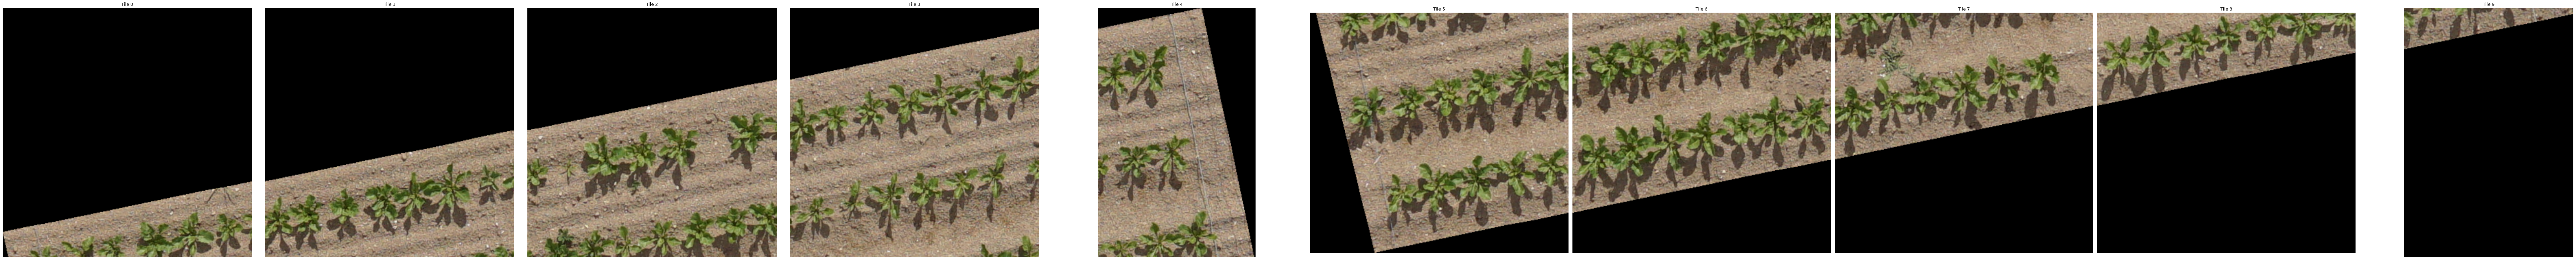

In [4]:
# Visualise first tiles

import matplotlib.pyplot as plt

nbTiles = 10
n_tiles = min(nbTiles, len(tiles))

fig, axes = plt.subplots(
    1,
    n_tiles,
    figsize=(nbTiles * n_tiles, nbTiles),
)

axes = np.atleast_1d(axes)

for i, ax in enumerate(axes):
    ax.imshow(tiles[i])
    ax.set_title(f"Tile {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Tile a raster image into smaller patches
tileSize=512
from opencropphenotyping.io import tile_raster
tiles = tile_raster(
    input_path=dataset_segmentation_dir/"103_DSC01167.tif",
    output_dir=output_dir,
    tile_size=tileSize,
)

print("Number of tiles:", len(tiles))
print("First tile:", tiles[0])

Number of tiles: 10
First tile: c:\Users\aurel\Documents\GitHub\OpenCropPhenotyping\data\processed\tiling_test\103_DSC01167_r00000_c00000.tif


In [8]:
# Check that the tiles have the same CRS and transform as the source raster

import rasterio
with rasterio.open(dataset_segmentation_dir/"103_DSC01167.tif") as src:
    source_crs = src.crs
    source_transform = src.transform

with rasterio.open(tiles[0]) as tile:
    print("Source CRS:", source_crs)
    print("Tile CRS:", tile.crs)

    print("Source transform:", source_transform)
    print("Tile transform:", tile.transform)

    assert tile.crs == source_crs
    assert tile.transform == source_transform
    assert tile.width == tileSize
    assert tile.height == tileSize

Source CRS: EPSG:3857
Tile CRS: EPSG:3857
Source transform: | 1.00, 0.00, 0.00|
| 0.00,-1.00, 987.00|
| 0.00, 0.00, 1.00|
Tile transform: | 1.00, 0.00, 0.00|
| 0.00,-1.00, 987.00|
| 0.00, 0.00, 1.00|
